In [23]:
import pandas as pd
d = pd.read_csv("../data/clean.csv")["appointment_date_continuous"]
print(d.min(), "to", d.max())
print("unique days:", d.nunique())

2020-01-01 to 2021-05-12
unique days: 498


Encoding: one-hot for specialty, gender, disability, shift, rain, heat and age group. place has 26,290 unique values, mostly rare one-off names, so it is grouped into the top 10 places plus “Other” and “Unknown”. Frequency encoding was dropped because it was not meaningful.

In [21]:
df.to_csv("../data/clean.csv", index=False)
df_model.to_csv("../data/model_ready.csv", index=False)

In [20]:
df["gender"].value_counts(dropna=False)

gender
M    82269
F    27077
I      247
Name: count, dtype: int64

In [19]:
top_places = df["place"].value_counts().head(10).index
df["place_group"] = np.where(df["place"].isin(top_places), df["place"], "Other")
print(df["place_group"].value_counts())

place_dummies = pd.get_dummies(df["place_group"], prefix="place", drop_first=True)
df_model = pd.concat([df_model, place_dummies], axis=1)

# remove the weak frequency feature and the duplicate of place_Unknown
df_model = df_model.drop(columns=["place_freq", "place_unknown"], errors="ignore")
print(df_model.shape)

place_group
Other             54791
ITAJAÍ            20515
Unknown           11539
B. CAMBORIU        6018
CAMBORIU           5523
NAVEGANTES         3901
ITAPEMA            2665
BOMBINHAS          1707
PENHA              1039
PORTO BELO          950
BALN. PIÇARRAS      945
Name: count, dtype: int64
(109593, 62)


In [18]:
df.to_csv("../data/clean.csv", index=False)               # with dates, for forecasting
df_model.to_csv("../data/model_ready.csv", index=False)   # encoded, for classification

In [17]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print(cat_cols)

for c in cat_cols:
    print(c, df[c].nunique())

small_cols = ["specialty", "gender", "disability", "appointment_shift",
              "rain_intensity", "heat_intensity", "age_group"]
df_model = pd.get_dummies(df, columns=small_cols, drop_first=True)
place_freq = df_model["place"].value_counts(normalize=True)
df_model["place_freq"] = df_model["place"].map(place_freq)
df_model = df_model.drop(columns=["place"])

df_model = df_model.drop(columns=["appointment_date_continuous"])
print(df_model.shape)
print(df_model.dtypes.value_counts())

['specialty', 'gender', 'disability', 'place', 'appointment_shift', 'rain_intensity', 'heat_intensity', 'age_group']
specialty 9
gender 3
disability 3
place 26290
appointment_shift 2
rain_intensity 4
heat_intensity 5
age_group 5
(109593, 54)
bool       24
int64      21
float64     6
int32       3
Name: count, dtype: int64


Features created: day_of_week, month, week_of_year, day_of_month, is_weekend (from the date); age_group (0-12, 13-18, 19-40, 41-60, 60+); young_adult; place_unknown, specialty_unknown, disability_unknown and missing_count (since missingness was a strong signal in EDA); age_missing.
Day of week: no-show rate is ~31 to 33% on every day, so no strong effect.

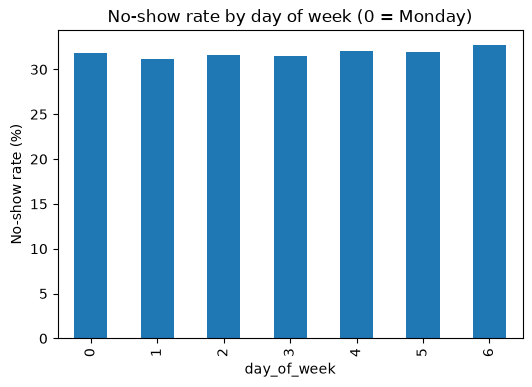

In [12]:
rate = df.groupby("day_of_week")["no_show"].mean() * 100
rate.plot(kind="bar", figsize=(6, 4))
import matplotlib.pyplot as plt
plt.ylabel("No-show rate (%)")
plt.title("No-show rate by day of week (0 = Monday)")
plt.show()

In [11]:
print(df.shape)
df[["appointment_date_continuous", "day_of_week", "month", "is_weekend", "age", "age_group", "missing_count"]].head()

(109593, 38)


,appointment_date_continuous,day_of_week,month,is_weekend,age,age_group,missing_count
0,2020-01-01,2,1,0,9.0,0-12,0
1,2020-01-01,2,1,0,11.0,0-12,1
2,2020-01-01,2,1,0,8.0,0-12,0
3,2020-01-01,2,1,0,9.0,0-12,0
4,2020-01-01,2,1,0,12.0,0-12,0


a couple of interaction features

In [10]:
# young adults (the highest-risk group) with unknown place
df["young_adult"] = ((df["age"] > 18) & (df["age"] <= 40)).astype(int)
df["place_unknown"] = (df["place"] == "Unknown").astype(int)
df["specialty_unknown"] = (df["specialty"] == "Unknown").astype(int)
df["disability_unknown"] = (df["disability"] == "Unknown").astype(int)

# how many of the three key fields are missing (0 to 3)
df["missing_count"] = df["place_unknown"] + df["specialty_unknown"] + df["disability_unknown"]

age group

In [9]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[-1, 12, 18, 40, 60, 120],
    labels=["0-12", "13-18", "19-40", "41-60", "60+"]
).astype(str)

date features

In [8]:
d = df["appointment_date_continuous"]
df["day_of_week"] = d.dt.dayofweek          # 0 = Monday ... 6 = Sunday
df["month"] = d.dt.month
df["week_of_year"] = d.dt.isocalendar().week.astype(int)
df["day_of_month"] = d.dt.day
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

C:\Users\dhanu\AppData\Local\Temp\ipykernel_24504\3180540769.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = d.dt.dayofweek          # 0 = Monday ... 6 = Sunday


convert the date column

In [7]:
df["appointment_date_continuous"] = pd.to_datetime(df["appointment_date_continuous"])
print(df["appointment_date_continuous"].min(), "to", df["appointment_date_continuous"].max())

2020-01-01 00:00:00 to 2021-05-12 00:00:00


In [6]:
df.isnull().sum().sum()

np.int64(0)

weather columns, fill with median

In [5]:
weather_cols = ["average_temp_day", "average_rain_day", "max_temp_day", "max_rain_day"]
for col in weather_cols:
    df[col] = df[col].fillna(df[col].median())

age flag first, then fill

In [4]:
df["age_missing"] = df["age"].isnull().astype(int)   # flag BEFORE filling
df["age"] = df["age"].fillna(df["age"].median())

categorical columns, fill with “Unknown”

In [3]:
for col in ["specialty", "disability", "place"]:
    df[col] = df[col].fillna("Unknown")

target and blank fix

In [2]:
# target: yes/no -> 1/0
df["no_show"] = (df["no_show"] == "yes").astype(int)

# blank text -> missing (disability had 419 of these)
df["disability"] = df["disability"].replace(r"^\s*$", pd.NA, regex=True)

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/Medical_appointment_data.csv")
print(df.shape)

(109593, 26)
